In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from experiments.plots.plotly import get_prediction_plot, get_prediction_plots

ModuleNotFoundError: No module named 'experiments.plots'

In [3]:
config = {
    "_default": {
        "h":24,
        "p":24,
        "stride":24
    },
    "pv-italy": {
        "name": "pv-italy",
        "n":17,
        "f":12,
        "h":19,
        "p":19,
        "stride":19
    },
    "wind-nrel": {
        "name": "wind-nrel",
        "n":5,
        "f":8,
        "h":24,
        "p":24,
        "stride":24
    },
    "lightsource": {
        "name": "lightsource",
        "n":7,
        "f":11,
        "h":19,
        "p":19,
        "stride":19
    },
    "beijing-multisite-airquality": {
        "name": "beijing-multisite-airquality",
        "n":12,
        "f":11,
        "h":6,
        "p":6,
        "stride":6
    },
    "rainfall-eastcoast": {
        "name": "rainfall-eastcoast",
        "n":15,
        "f":16
    },
    "pems-sf-weather": {
        "name": "pems-sf-weather",
        "n":163,
        "f":16,
        "h":6,
        "p":6,
        "stride":6
    },
    "q-traffic": {
        "name": "q-traffic",
        "n":432,
        "f":6
    }
}

In [4]:
dataset = "pv-italy"
dataset_cfg = config[dataset]

In [ ]:
seq = 141

# Altieri Preds

In [ ]:
def plot_preds(truth, plot_name, preds = None):
    # plt.plot(preds, color="red", linewidth=1, alpha=0.4)
    plt.plot(truth, color="blue", linewidth=1, alpha=0.4)
    # plt.plot(np.mean(preds, axis=-1), color="red", linewidth=4)
    plt.plot(np.mean(truth, axis=-1), color="blue", linewidth=4)
    # plt.plot([], color="red", label="Predictions")
    plt.plot([], color="blue", label="Ground truth")
    plt.xlabel("Timesteps", fontsize=20)
    plt.ylabel("Target", fontsize=20)
    plt.xticks(
        np.arange(0, len(truth), 3), np.arange(0, len(truth), 3) + 1, fontsize=20
    )
    plt.yticks(fontsize=20)
    plt.legend(fontsize=18)
    plt.subplots_adjust(left=0.2, bottom=0.2)

    # plt.savefig(f"{plot_name}.png")
    # plt.savefig(f"{plot_name}.pdf")
    plt.show()

    plt.clf()

In [ ]:
df = pd.read_csv(f"../dvc-stages-outputs/{dataset}/test_dates/{dataset}.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4788 entries, 0 to 4787
Data columns (total 3 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               4788 non-null   int64  
 1   truth                    4788 non-null   float64
 2   S2S-GCLSTM-AT-BS4LR1e-3  4788 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 112.3 KB


In [ ]:
truth = df["truth"].to_numpy()
print("truth shape:", truth.shape)

truth shape: (4788,)


In [ ]:
T = dataset_cfg["p"]
N = dataset_cfg["n"]
reshaped_truth = np.reshape(truth[seq * T * N : (seq + 1) * T * N], (T, N))
print("truth shape:", reshaped_truth.shape)

ValueError: cannot reshape array of size 0 into shape (19,7)

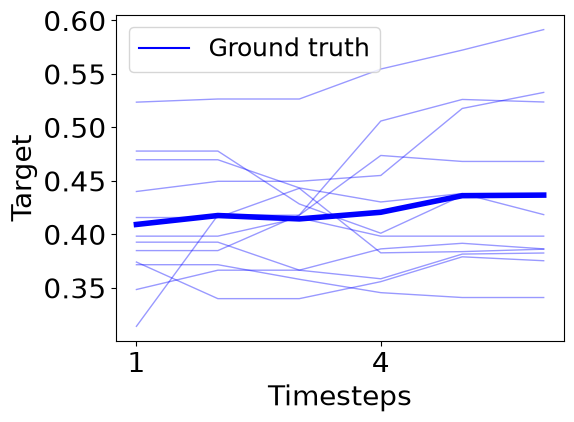

<Figure size 640x480 with 0 Axes>

In [ ]:
plot_preds(reshaped_truth, "test_plot")

# Repo

In [ ]:
import logging

from experiments.stages.prepare import obs2seqs

In [5]:
test_indexes_path = f"../dvc-stages-outputs/{dataset}/test_dates/{dataset}_0.1.npy"
test_indexes = np.load(test_indexes_path) - 1
print("Loaded test indexes with shape:", test_indexes.shape)
print("Test indexes:", test_indexes)

Loaded test indexes with shape: (85,)
Test indexes: [ 94  96 101 112 124 139 150 151 160 188 204 208 223 228 246 256 262 264
 273 275 276 282 288 293 306 307 308 321 339 340 343 353 361 374 382 391
 400 422 437 443 448 453 454 458 466 471 489 493 494 501 502 510 522 533
 535 545 548 569 575 577 588 593 617 630 634 641 644 647 663 686 687 731
 733 737 745 759 767 785 799 800 803 806 827 832 841]


In [6]:
val_indexes_path = f"../dvc-stages-outputs/{dataset}/test_dates/{dataset}_0.01.npy"
val_indexes = np.load(val_indexes_path) - 1
print("Loaded validation indexes with shape:", val_indexes.shape)
print("Validation indexes:", val_indexes)

Loaded validation indexes with shape: (8,)
Validation indexes: [170 220 347 480 608 720 746 812]


Let us assuming there is an order relationship between samples: $x < y$ if $date(x) < date(y)$.

In order to be data leakage free, all test samples $y$ should be greater than the minimum sample in the validation set $x$. 

However in this beijing-multisite-airquality split $x = 184$ is not less than $y \in \{102, 109, 110, 112, 118, 123, 126, 134, 138, 140, 145, 161, 165, 175\}$

In [1]:
import numpy as np
dataset = "pv-italy"
data_path = f"../dvc-stages-outputs/{dataset}/{dataset}.npz"
data = np.load(data_path)["data"]
print("Loaded data with shape:", data.shape)
print(data)
# X, Y = obs2seqs(logging.getLogger(), data, dataset_cfg["h"], dataset_cfg["p"], dataset_cfg["stride"])
# Y = Y[..., 0]
# print("Shape of X:", X.shape)
# print("Shape of Y:", Y.shape)

Loaded data with shape: (16264, 17, 12)
[[[0.    0.212 0.    ... 0.083 0.117 0.147]
  [0.    0.212 0.    ... 0.083 0.118 0.147]
  [0.    0.212 0.    ... 0.083 0.118 0.142]
  ...
  [0.    0.212 0.    ... 0.083 0.117 0.147]
  [0.    0.212 0.    ... 0.083 0.118 0.147]
  [0.    0.212 0.    ... 0.083 0.117 0.147]]

 [[0.    0.212 0.    ... 0.083 0.131 0.207]
  [0.    0.212 0.    ... 0.083 0.131 0.207]
  [0.    0.212 0.    ... 0.083 0.133 0.211]
  ...
  [0.    0.212 0.    ... 0.083 0.131 0.207]
  [0.    0.212 0.    ... 0.083 0.131 0.207]
  [0.    0.212 0.    ... 0.083 0.131 0.207]]

 [[0.    0.212 0.    ... 0.083 0.175 0.27 ]
  [0.    0.212 0.    ... 0.083 0.176 0.27 ]
  [0.    0.212 0.    ... 0.083 0.178 0.272]
  ...
  [0.    0.212 0.    ... 0.083 0.175 0.27 ]
  [0.    0.212 0.    ... 0.083 0.176 0.554]
  [0.    0.212 0.    ... 0.083 0.176 0.554]]

 ...

 [[0.    0.47  0.    ... 0.083 0.678 0.749]
  [0.    0.424 0.    ... 0.083 0.678 0.749]
  [0.    0.455 0.    ... 0.75  0.675 0.555]
  ...


In [ ]:
# find the reshape_truth in Y
index = None
for i, y in enumerate(Y):
    if np.array_equal(y, reshaped_truth):
        print("Found reshaped_truth in Y")
        index = i
        break
print("Index of reshaped_truth in Y:", index)

Found reshaped_truth in Y
Index of reshaped_truth in Y: 1443


In [ ]:
y_test = Y[test_indexes]
print("Loaded test data with shape:", y_test.shape)

Loaded test data with shape: (146, 6, 12)


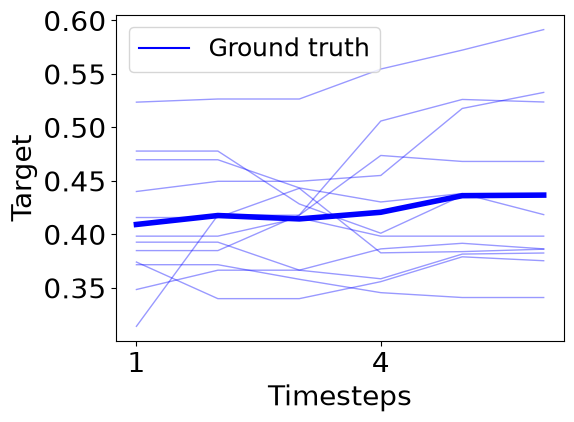

<Figure size 640x480 with 0 Axes>

In [ ]:
plot_preds(y_test[seq], "test_plot")

In [ ]:
fig = get_prediction_plot(y_test[seq])
fig.show()